# Loading setup

In [1]:
import os
import numpy as np
import pandas as pd
import regex
from Bio import Entrez, SeqIO, SeqUtils
import time
import matplotlib.pyplot as plt
import random as rand
import scipy.stats as stats
import re
import xml.etree.ElementTree as ET
import seaborn as sns
from matplotlib.colors import ListedColormap
import matplotlib.cm as cm

%matplotlib inline

In [2]:
#import GapR phage/host table
GapRphage = pd.read_csv('./data/GapRphage-host-merge.csv')
GapRphage[0:3]

,Phage Protein Name,Sequence,Host,Taxonomy,Phagegroup,Length,Protein Acession,Phage KR_count,Nearest Host Accession,Host GapR,Host GapR Sequence
0,BCZ75891.1 UPF0335 protein [Acetobacter phage ...,MTNDMTGHNSAATGGIAADRLRSLIERVERLEEERKALAGDIKDIF...,Acetobacter,Viruses; Duplodnaviria; Heunggongvirae; Urovir...,Caudoviricetes,89,BCZ75891.1,7,GCA_004341595.1,>WP_018307807.1 MULTISPECIES: DUF2312 domain-c...,MSDVPFDIDDDAAASRARQAADPESNVGGIAADRLRSIIERVERLE...
1,YP_007006471.1 hypothetical protein F406_gp102...,MSTIGHNSGETTETVAAAELRQFIERVERLEEEKAAIQGDIKDVMS...,Agrobacterium,Viruses; Duplodnaviria; Heunggongvirae; Urovir...,Schmittlotzvirus,102,YP_007006471.1,6,GCA_000192635.1,>WP_006314683.1 MULTISPECIES: DUF2312 domain-c...,MMDETSTTETVAAAELRQFIERVERLEEEKAAIQGDIKDVMGEAKG...
2,QIW87535.1 hypothetical protein Ab1vBOLIVR4_gp...,MSGIGHNSGETTETIAAAELRQFIERWERLEEEKRAIASDQKDIMG...,Agrobacterium,Viruses; Duplodnaviria; Heunggongvirae; Urovir...,Schmittlotzvirus,102,QIW87535.1,7,GCA_027871525.1,>WP_006314683.1 MULTISPECIES: DUF2312 domain-c...,MMDETSTTETVAAAELRQFIERVERLEEEKAAIQGDIKDVMGEAKG...


###Exclude Proteins from downstream analysis:
>AEI71053.1 hypothetical protein [EBPR siphovirus 2] / is metagenome sampled
>ANR76363.1 hypothetical protein AUR56_00018 [Skeletonema virus LDF-2015a] / host genome size is flagged as too large

In [3]:
GapRphage.loc[54, 'Host'] = 'uncultured' #redefine AEI71053.1 hypothetical protein [EBPR siphovirus 2] as uncultured
GapRphage.loc[154, 'Host'] = 'uncultured' #redefine ANR76363.1 hypothetical protein AUR56_00018 [Skeletonema virus LDF-2015a] as uncultured

#proof
GapRphage.iloc[[54,154]]

,Phage Protein Name,Sequence,Host,Taxonomy,Phagegroup,Length,Protein Acession,Phage KR_count,Nearest Host Accession,Host GapR,Host GapR Sequence
54,AEI71053.1 hypothetical protein [EBPR siphovir...,MARKPGEEPTSKDNGGDDPVAGDRLKTIAERINRLEEEKKAIADDI...,uncultured,Viruses; Duplodnaviria; Heunggongvirae; Urovir...,Caudoviricetes,97,AEI71053.1,5,NaN,NaN,NaN
154,ANR76363.1 hypothetical protein AUR56_00018 [S...,MTDETPGQGHNSYGLAAGELRQFIERVEHLEAEKREIAEQVKEVMA...,uncultured,Viruses,Viruses,96,ANR76363.1,6,GCA_046619385.1,NaN,NaN


## Figure 7A
Writes out phage and host GapRs to fasta to build tree

In [9]:
#write out phages with hosts to fasta format for tree
filtered_phages = GapRphage[GapRphage['Host'] != 'uncultured']

fasta_output_lines = []
for index, row in filtered_phages.iterrows():
    protein_name = row['Phage Protein Name']
    sequence = row['Sequence']
    fasta_output_lines.append(f">{protein_name}\n{sequence}")

# Drop duplicates to keep only unique Host GapR sequences and their corresponding names
unique_hosts = filtered_phages.dropna(subset=['Host GapR', 'Host GapR Sequence']).drop_duplicates(subset=['Host GapR'])

for index, row in unique_hosts.iterrows():
    protein_name = row['Host GapR']
    sequence = row['Host GapR Sequence']
    fasta_output_lines.append(f"{protein_name}\n{sequence}")

# Write the FASTA output to a file
with open('phages_with_hosts.fasta', 'w') as f:
    f.write("\n".join(fasta_output_lines))

## Figure 7B, calculate %GC of host/phage GapRs


### Download all host/phage genome sequences locally

In [10]:
#query NCBI to get phage genome accession ID & GapR location
Entrez.email = "msguo@uw.edu"
phagegenome = []
genomeLocation = []

for index, row in GapRphage.iterrows(): # Iterate over all rows
    protein_name_words = row['Phage Protein Name'].split(' ')
    accession = protein_name_words[0]

    try:
      handle = Entrez.efetch(db="protein", id=accession, rettype="xml")
      record = ET.parse(handle)
      root = record.getroot()

      sourcedb_text = root.find(".//GBSeq_source-db").text
      if sourcedb_text:
          # Split by space and take the last element to get the accession number
          phagegenome.append(sourcedb_text.split(' ')[-1])
      else:
          # If 'GBSeq_source-db' element is not found or its text is empty
          phagegenome.append('N/A_sourcedb_info')

      for qualifier in root.findall(".//GBQualifier"):
            name_elem = qualifier.find("GBQualifier_name")
            if name_elem is not None and name_elem.text == "coded_by":
                value_elem = qualifier.find("GBQualifier_value")
                if value_elem is not None:
                    coded_by = value_elem.text
                    break

      genomeLocation.append(coded_by)
      time.sleep(1)  # Be nice to NCBI

    except Exception as e:
      phagegenome.append(accession)
      print(f'yikes! Failed to fetch/parse for accession {accession}. Error: {e}')

GapRphage['Phage Accession'] = phagegenome
GapRphage['Genome Location'] = genomeLocation

In [ ]:
#downloads phage genomes via curl to NCBI into "phage-genomes" folder
Pnames = GapRphage['Phage Accession'].values
for x in Pnames:
  print(x)
  dlstring = "curl 'https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=nuccore&id={}&rettype=fasta&retmode=text' > ./data/phage-genomes/{}.txt".format(x,x)
  #print(dlstring)
  os.system(dlstring)
  time.sleep(1)  # Be nice to NCBI, this is a LONG sleep to ensure no empty files

In [11]:
#check phage downloads correct
print(len(os.listdir('./data/phage-genomes'))) #only 287 because there are two GapRs in PX284261.1
print(len(GapRphage['Phage Accession'].values))

287
288


###Unfortunately, I didn't automate downloading host genomes here, but it's a short matrix to check & download manually through ncbi-genome-download: https://github.com/maxibor/ncbi-genome-download

In [12]:
#finds host fasta files from NCBI in the list Pnames
Pnames = GapRphage[(GapRphage['Host'] != 'uncultured') & (GapRphage['Nearest Host Accession'].notna())]['Nearest Host Accession'].values

# Create a new list with 'GCA' replaced by 'GCF'
formatted_pnames = [p.replace('GCA', 'GCF') for p in Pnames]

# Write the formatted Pnames to a file, one per line
with open('host_GCF.txt', 'w') as f:
    for name in formatted_pnames:
        f.write(name + '\n')

##Calculate phage/host GC content

In [13]:
#calculates %GC of phage & host genomes
phages = os.listdir('./data/phage-genomes')
phage_gc = []
for name in phages:
  with open('./phage-genomes/'+ name) as handle:
      for record in SeqIO.parse(handle, "fasta"):
          #print(record.id)
          phage_gc.append(SeqUtils.gc_fraction(record.seq))
      handle.close()

hosts = os.listdir('./data/host-genomes')
host_gc = []
for name in hosts:
  total_gc_product = 0
  total_length = 0
  with open('./host-genomes/'+ name) as handle:
      for record in SeqIO.parse(handle, "fasta"):
          seq_len = len(record.seq)
          gc_frac = SeqUtils.gc_fraction(record.seq)
          total_gc_product += (gc_frac * seq_len)
          total_length += seq_len
      handle.close()
  if total_length > 0: #to handle fragmentary or multi-chromosome genomes
      host_gc.append(total_gc_product / total_length)
      #print(name)
  else:
      host_gc.append(np.nan) # handle cases where a file might be empty
      print(name,'empty!!')

In [14]:
#merge matrices
GCmatrix = pd.DataFrame([phages,phage_gc]).transpose()
GCmatrix.columns = ['phage_file', 'GC_content']
GCmatrix['Phage Accession'] = GCmatrix['phage_file'].str.replace('.txt', '', regex=False)

GapRphageGC = pd.merge(GapRphage, GCmatrix, on='Phage Accession', how='inner')

GChostmatrix = pd.DataFrame([hosts, host_gc]).transpose()
GChostmatrix.columns = ['host_file', 'host_GC_content']

# Extract only the numerical part of the accession ID from 'nearest host accession' for merged_df
GapRphageGC['host_accession_id'] = GapRphageGC['Nearest Host Accession'].str.extract(r'([0-9]+\.[0-9]+)', expand=False)

# Extract only the numerical part of the accession ID from 'host_file' for GChostmatrix
GChostmatrix['host_accession_id'] = GChostmatrix['host_file'].str.extract(r'GC[AF]_([0-9]+\.[0-9]+)', expand=False)

#merge
GapRGC = pd.merge(GapRphageGC, GChostmatrix[['host_accession_id', 'host_GC_content']], on='host_accession_id', how='left')
GapRGC.drop_duplicates(inplace=True)
GapRGC.reset_index(drop=True, inplace=True)
len(GapRGC)

288

In [15]:
GapRGC[0:2]

,Phage Protein Name,Sequence,Host,Taxonomy,Phagegroup,Length,Protein Acession,Phage KR_count,Nearest Host Accession,Host GapR,Host GapR Sequence,Phage Accession,Genome Location,phage_file,GC_content,host_accession_id,host_GC_content
0,BCZ75891.1 UPF0335 protein [Acetobacter phage ...,MTNDMTGHNSAATGGIAADRLRSLIERVERLEEERKALAGDIKDIF...,Acetobacter,Viruses; Duplodnaviria; Heunggongvirae; Urovir...,Caudoviricetes,89,BCZ75891.1,7,GCA_004341595.1,>WP_018307807.1 MULTISPECIES: DUF2312 domain-c...,MSDVPFDIDDDAAASRARQAADPESNVGGIAADRLRSIIERVERLE...,LC644973.1,LC644973.1:16021..16290,LC644973.1.txt,0.560471,004341595.1,0.570679
1,YP_007006471.1 hypothetical protein F406_gp102...,MSTIGHNSGETTETVAAAELRQFIERVERLEEEKAAIQGDIKDVMS...,Agrobacterium,Viruses; Duplodnaviria; Heunggongvirae; Urovir...,Schmittlotzvirus,102,YP_007006471.1,6,GCA_000192635.1,>WP_006314683.1 MULTISPECIES: DUF2312 domain-c...,MMDETSTTETVAAAELRQFIERVERLEEEKAAIQGDIKDVMGEAKG...,NC_019519.1,complement(NC_019519.1:11653..11961),NC_019519.1.txt,0.523771,000192635.1,0.585411


In [16]:
phageLoc = []
gapR_gc = []
for index, row in GapRGC.iterrows():
    phageLoc.append(row['Phage Accession'])
    genome_location_str = str(row['Genome Location']) # Ensure it's a string

    # Default values in case of parsing failure
    genome_acc = None
    start_coord = None
    end_coord = None

    # Check for complement and parse accordingly
    if genome_location_str.startswith('complement('):
        match = re.search(r'complement\((.*?):(\d+)(?:\.\.|\.\.>)(\d+)\)', genome_location_str)
        if match:
            genome_acc = match.group(1)
            start_coord = int(match.group(2))
            end_coord = int(match.group(3))
    else:
        match = re.search(r'(.*?):(\d+)(?:\.\.|\.\.>)(\d+)', genome_location_str)
        if match:
            genome_acc = match.group(1)
            start_coord = int(match.group(2))
            end_coord = int(match.group(3))

    if genome_acc and start_coord is not None and end_coord is not None:
        # Construct filename using the extracted phage accession
        phage_filename = f"{genome_acc}.txt"
        full_path = os.path.join('./data/phage-genomes/', phage_filename)

        try:
            if not os.path.exists(full_path):
                print(f"Warning: Phage genome file not found: {full_path}. Skipping.")
                gapR_gc.append(np.nan)
                continue

            with open(full_path) as handle:
                found_record = False
                for record in SeqIO.parse(handle, "fasta"):
                    if record.id == genome_acc: # Match record ID to accession
                        # Adjust to 0-based indexing for Python slicing
                        segment = record.seq[start_coord - 1 : end_coord]
                        gapR_gc.append(SeqUtils.gc_fraction(segment))
                        found_record = True
                        break
                if not found_record:
                    print(f"Warning: Record {genome_acc} not found within file {phage_filename}. Skipping.")
                    gapR_gc.append(np.nan)
        except Exception as e:
            print(f"Error processing {phage_filename} for {genome_location_str}: {e}. Skipping.")
            gapR_gc.append(np.nan)
    else:
        print(f"Warning: Could not parse genomeLocation: {genome_location_str}. Skipping.")
        gapR_gc.append(np.nan)

In [17]:
tempMat = pd.DataFrame([phageLoc, gapR_gc]).transpose()
tempMat.columns = ['Phage Accession', 'GapR%GC']
GapRGC = GapRGC.merge(tempMat[['Phage Accession', 'GapR%GC']], on='Phage Accession', how='left')

In [18]:
GapRGC[0:2]

,Phage Protein Name,Sequence,Host,Taxonomy,Phagegroup,Length,Protein Acession,Phage KR_count,Nearest Host Accession,Host GapR,Host GapR Sequence,Phage Accession,Genome Location,phage_file,GC_content,host_accession_id,host_GC_content,GapR%GC
0,BCZ75891.1 UPF0335 protein [Acetobacter phage ...,MTNDMTGHNSAATGGIAADRLRSLIERVERLEEERKALAGDIKDIF...,Acetobacter,Viruses; Duplodnaviria; Heunggongvirae; Urovir...,Caudoviricetes,89,BCZ75891.1,7,GCA_004341595.1,>WP_018307807.1 MULTISPECIES: DUF2312 domain-c...,MSDVPFDIDDDAAASRARQAADPESNVGGIAADRLRSIIERVERLE...,LC644973.1,LC644973.1:16021..16290,LC644973.1.txt,0.560471,004341595.1,0.570679,0.574074
1,YP_007006471.1 hypothetical protein F406_gp102...,MSTIGHNSGETTETVAAAELRQFIERVERLEEEKAAIQGDIKDVMS...,Agrobacterium,Viruses; Duplodnaviria; Heunggongvirae; Urovir...,Schmittlotzvirus,102,YP_007006471.1,6,GCA_000192635.1,>WP_006314683.1 MULTISPECIES: DUF2312 domain-c...,MMDETSTTETVAAAELRQFIERVERLEEEKAAIQGDIKDVMGEAKG...,NC_019519.1,complement(NC_019519.1:11653..11961),NC_019519.1.txt,0.523771,000192635.1,0.585411,0.498382


## Generate 7B, GapR%GC vs phage %GC




uncultured:  PearsonRResult(statistic=np.float64(0.95932505092391), pvalue=np.float64(6.114206114769981e-86))
known host:  PearsonRResult(statistic=np.float64(0.9081470577125432), pvalue=np.float64(3.861335124264271e-52))
all:  PearsonRResult(statistic=np.float64(0.9536267032631406), pvalue=np.float64(3.281823258071001e-152))


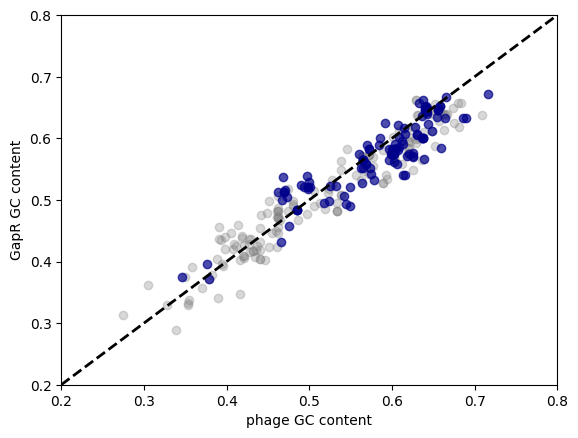

In [20]:
#make GapR%GC vs phage %GC plot,separated by cultured vs uncultured
plt.plot([0.2, 0.8], [0.2, 0.8], linestyle='--', color='black', linewidth=2, label='y=x')
plt.scatter(GapRGC[GapRGC['Host'] == 'uncultured']['GC_content'],GapRGC[GapRGC['Host'] == 'uncultured']['GapR%GC'], color = 'grey', alpha = 0.3)
plt.scatter(GapRGC[GapRGC['Host'] != 'uncultured']['GC_content'],GapRGC[GapRGC['Host'] != 'uncultured']['GapR%GC'], color = 'darkblue', alpha = 0.7)
plt.xlim(0.2, 0.8)
plt.ylim(0.2, 0.8)
plt.xlabel('phage GC content')
plt.ylabel('GapR GC content')

#plt.savefig('./Figure7B-GapRvsPhageGC.pdf')

print('uncultured: ', stats.pearsonr(pd.to_numeric(GapRGC[GapRGC['Host'] == 'uncultured']['GC_content']), pd.to_numeric(GapRGC[GapRGC['Host'] == 'uncultured']['GapR%GC'])))
print('known host: ', stats.pearsonr(pd.to_numeric(GapRGC[GapRGC['Host'] != 'uncultured']['GC_content']), pd.to_numeric(GapRGC[GapRGC['Host'] != 'uncultured']['GapR%GC'])))
print('all: ', stats.pearsonr(pd.to_numeric(GapRGC['GC_content']), pd.to_numeric(GapRGC['GapR%GC'])))

## Generate S8A, GapR%GC vs phage host %GC


known host:  PearsonRResult(statistic=np.float64(0.26580013932335567), pvalue=np.float64(0.0018341679221541467))


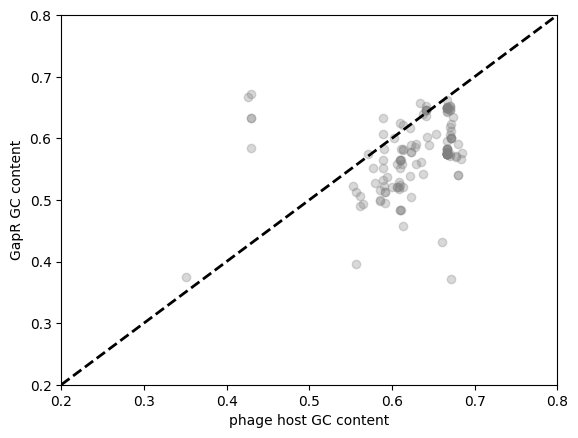

In [21]:
#make GapR%GC vs phage host %GC plot
plt.plot([0.2, 0.8], [0.2, 0.8], linestyle='--', color='black', linewidth=2, label='y=x')
plt.scatter(GapRGC[GapRGC['Host'] != 'uncultured']['host_GC_content'],GapRGC[GapRGC['Host'] != 'uncultured']['GapR%GC'], color = 'grey', alpha = 0.3)
plt.xlim(0.2, 0.8)
plt.ylim(0.2, 0.8)
plt.xlabel('phage host GC content')
plt.ylabel('GapR GC content')

#plt.savefig('./FigureS8A-GapRvsPhageHostGC.pdf')

print('known host: ', stats.pearsonr(pd.to_numeric(GapRGC[GapRGC['Host'] != 'uncultured']['host_GC_content']), pd.to_numeric(GapRGC[GapRGC['Host'] != 'uncultured']['GapR%GC'])))

## Generate 7C, phage %GC vs phage host %GC


known host:  PearsonRResult(statistic=np.float64(0.27698272746438146), pvalue=np.float64(0.0011451750133184338))
random host:  PearsonRResult(statistic=np.float64(-0.06463480638929657), pvalue=np.float64(0.4564020392632641))


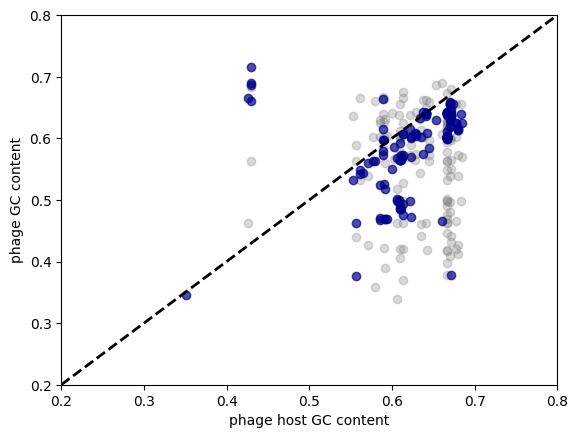

In [22]:
#make GapR%GC vs phage %GC plot,separated by cultured vs uncultured
plt.plot([0.2, 0.8], [0.2, 0.8], linestyle='--', color='black', linewidth=2, label='y=x')

# Sample random phages based on # phages with host, no replacement
random_phage_subset = GapRGC.sample(n=len(GapRGC[GapRGC['Host']!='uncultured']), replace=False).reset_index(drop=True)

# Now sample random hosts, with replacement
random_host_subset = GapRGC[GapRGC['Host'] != 'uncultured'].sample(n=len(GapRGC[GapRGC['Host']!='uncultured']), replace=True).reset_index(drop=True)

plt.scatter(random_host_subset['host_GC_content'], random_phage_subset['GC_content'], color = 'grey', alpha = 0.3)
plt.scatter(GapRGC[GapRGC['Host'] != 'uncultured']['host_GC_content'], GapRGC[GapRGC['Host'] != 'uncultured']['GC_content'], color='darkblue', alpha=0.7)

#aesthetics
plt.xlim(0.2, 0.8)
plt.ylim(0.2, 0.8)
plt.xlabel('phage host GC content')
plt.ylabel('phage GC content')

#plt.savefig('./Figure7C-PhagevsHostGC.pdf')

print('known host: ', stats.pearsonr(pd.to_numeric(GapRGC[GapRGC['Host'] != 'uncultured']['host_GC_content']), pd.to_numeric(GapRGC[GapRGC['Host'] != 'uncultured']['GC_content'])))
print('random host: ', stats.pearsonr(pd.to_numeric(random_host_subset['host_GC_content']), pd.to_numeric(random_phage_subset['GC_content'])))

## Generate 7D, phage vs host DNA-binding residues

In [23]:
#write out hosts to fasta format for tree
filtered_phages = GapRphage[GapRphage['Host'] != 'uncultured']

# Drop duplicates to keep only unique Host GapR sequences and their corresponding names
unique_hosts = filtered_phages.dropna(subset=['Host GapR', 'Host GapR Sequence']).drop_duplicates(subset=['Host GapR'])

fasta_output_lines = []
for index, row in unique_hosts.iterrows():
    protein_name = row['Host GapR']
    sequence = row['Host GapR Sequence']
    fasta_output_lines.append(f"{protein_name}\n{sequence}")

# Write the FASTA output to a file
with open('hosts.fasta', 'w') as f:
    f.write("\n".join(fasta_output_lines))

In [24]:
alignment_data = []
current_protein_name = None
current_aligned_sequence = []

file_path = './data/hosts-align.txt'

with open(file_path, 'r') as f:
    for line in f:
        line = line.strip()
        if line.startswith('>'):
            if current_protein_name is not None:
                alignment_data.append({
                    'Protein Name': current_protein_name,
                    'Aligned Sequence': ''.join(current_aligned_sequence)
                })
            current_protein_name = line[1:].strip()
            current_aligned_sequence = []
        elif line:
            current_aligned_sequence.append(line)

    # Add the last protein record after the loop finishes
    if current_protein_name is not None:
        alignment_data.append({
            'Protein Name': current_protein_name,
            'Aligned Sequence': ''.join(current_aligned_sequence)
        })

df_alignment = pd.DataFrame(alignment_data)

# Split the 'Aligned Sequence' into individual amino acid columns more efficiently
if not df_alignment.empty:
    # Create a DataFrame from the split sequences
    split_sequences_df = df_alignment['Aligned Sequence'].apply(lambda x: pd.Series(list(x)))
    # Rename columns to AA_1, AA_2, etc.
    split_sequences_df.columns = [f'AA_{i+1}' for i in range(split_sequences_df.shape[1])]

    # Concatenate 'Protein Name' with the new amino acid DataFrame
    df_alignment = pd.concat([df_alignment['Protein Name'], split_sequences_df], axis=1)

In [25]:
#find Caulobacter (NA1000) GapR column
df_alignment[df_alignment['Protein Name'].str.contains('NA1000')]

,Protein Name,AA_1,AA_2,AA_3,AA_4,AA_5,AA_6,AA_7,AA_8,AA_9,...,AA_139,AA_140,AA_141,AA_142,AA_143,AA_144,AA_145,AA_146,AA_147,AA_148
8,YP_002518801.1/1-89 chromosome binding protein...,-,-,-,-,-,-,-,-,-,...,I,-,-,-,-,-,-,-,-,-


In [26]:
# Select only the 'AA_' columns from the row
aa_columns_data = df_alignment.iloc[8][df_alignment.iloc[8].index.str.startswith('AA_')]

# Find columns where the value is not '-'
#gotta find K34, 42, 49, 56, 59, 63, 66 in Ccres GapR
#this parses to AA_84, AA_92, AA_99, AA_106, AA_109, AA_113, AA_116
aa_columns_data[aa_columns_data != '-'][65:66]

,8
AA_116,K


In [27]:
selected_cols = ['Protein Name', 'AA_84', 'AA_92', 'AA_99', 'AA_106', 'AA_109', 'AA_113', 'AA_116']
df_subset = df_alignment[selected_cols].copy()
df_subset['KR_count_host'] = df_subset.apply(lambda row: row.isin(['K', 'R']).sum(), axis=1)
df_subset['Host Protein Acession'] = df_subset['Protein Name'].apply(lambda x: x.split('/')[0])

In [28]:
df_subset[df_subset['KR_count_host']<4] #this is a GapR missing a2/3


,Protein Name,AA_84,AA_92,AA_99,AA_106,AA_109,AA_113,AA_116,KR_count_host,Host Protein Acession
19,TWI26937.1/1-90 uncharacterized protein DUF231...,K,K,K,-,-,-,-,3,TWI26937.1


In [29]:
GapRGC['Host Protein Acession'] = GapRGC['Host GapR'].astype(str).apply(lambda x: x.split(' ')[0][1:] if pd.notna(x) else 'n/a')
final_merged_df = pd.merge(GapRGC, df_subset[['Host Protein Acession', 'KR_count_host']], on='Host Protein Acession', how='left')

/tmp/ipykernel_1424/261455872.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_blues = cm.get_cmap('Purples', 256)


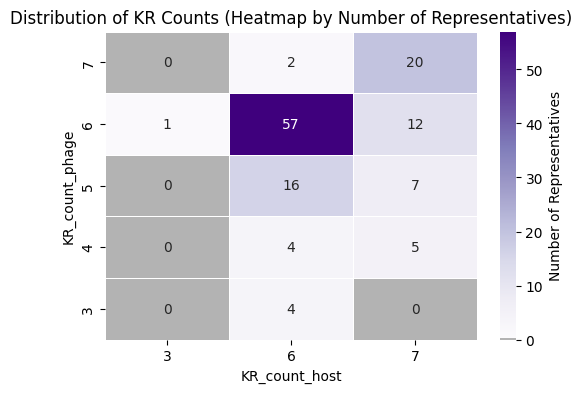

In [32]:
# The context indicates these might be object types from merges, so convert to float then nullable int
final_merged_df['Phage KR_count'] = final_merged_df['Phage KR_count'].astype(float).astype(pd.Int64Dtype())
final_merged_df['KR_count_host'] = final_merged_df['KR_count_host'].astype(float).astype(pd.Int64Dtype())

# Drop rows where either KR_count is NaN for plotting discrete integer values
plot_df_cleaned = final_merged_df.dropna(subset=['Phage KR_count', 'KR_count_host'])

# Aggregate data to get counts for the heatmap
grouped_counts = plot_df_cleaned.groupby(['Phage KR_count', 'KR_count_host']).size().reset_index(name='count')

# Pivot the table to prepare for heatmap
heatmap_data = grouped_counts.pivot_table(index='Phage KR_count', columns='KR_count_host', values='count').fillna(0)

# Create a custom colormap: black for 0, then standard Blues for positive values
cmap_blues = cm.get_cmap('Purples', 256)
new_colors = cmap_blues(np.linspace(0, 1, 256))
new_colors[0, :] = [0.7, 0.7, 0.7, 1]
custom_cmap = ListedColormap(new_colors)

plt.figure(figsize=(6, 4)) # Make the figure smaller
sns.heatmap(heatmap_data,
            annot=True, # Annotate cells with the count
            fmt='.0f', # Format annotations as integers without decimals
            cmap=custom_cmap, # Use the custom colormap
            linewidths=.5, # Add lines between cells
            cbar_kws={'label': 'Number of Representatives'},
            vmin=0) # Ensure 0 maps to the first color (black)

# Add labels and title for clarity
plt.xlabel('KR_count_host')
plt.ylabel('KR_count_phage')
plt.title('Distribution of KR Counts (Heatmap by Number of Representatives)')

# Invert y-axis to have lower KR_count_y at the bottom, matching typical scatter plot orientation
plt.gca().invert_yaxis()

#plt.savefig('Figure7D-host-phage-heatmap.pdf')
plt.show()

##Figure 7E

In [40]:
#merge in phage group information
phage_group = pd.read_csv('./data/phage-group-categorization.csv')
GapRGC = GapRGC.merge(phage_group, on='Phage Protein Name', how='left')

In [44]:
pairs = GapRGC[GapRGC['Host'] != 'uncultured'].copy()
pairs.dropna(subset=['Host GapR Sequence'], inplace=True) #leave out Mycrocystis, Synechococcus, Pseudomonas hits

host_length = []
for i,j in pairs.iterrows():
  host_length.append(len(j['Host GapR Sequence']))

pairs['Host GapR Length'] = host_length

PearsonRResult(statistic=np.float64(-0.23866828359558973), pvalue=np.float64(0.006666532469409685))

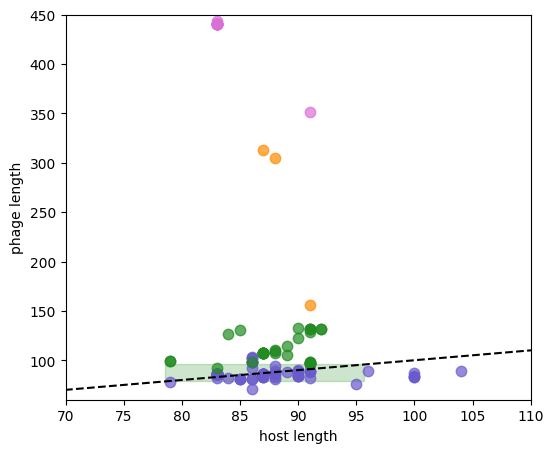

In [54]:
plt.figure(figsize=(6,5))

# Define colors and labels for each host group
host_groups = [1.0, 2.0, 3.0, 4.0]
colors = ['slateblue', 'forestgreen', 'darkorange', 'orchid']

# Plot data with colors
for i, group in enumerate(host_groups):
    group_data = pairs[pairs['Phage group'] == group]
    plt.plot(group_data['Host GapR Length'], group_data['Length'],
             '.', color=colors[i % len(colors)], label=f'Group {int(group)}', alpha=0.7, markersize=15)

plt.xlabel('host length')
plt.ylabel('phage length')
plt.ylim([60,450])
plt.xlim([70,110])
plt.plot([60, 120], [60, 120], 'k--')

# Calculate host length min and max
host_min_val = pairs['Host GapR Length'].mean()-2*pairs['Host GapR Length'].std()
host_max_val = pairs['Host GapR Length'].mean()+2*pairs['Host GapR Length'].std()

# Create the rectangle patch
# The square's x-range and y-range are defined by the host length limits
rect_x_start = host_min_val
rect_y_start = host_min_val
rect_side_length = host_max_val - host_min_val

rect = plt.Rectangle((rect_x_start, rect_y_start), rect_side_length, rect_side_length,
                     linewidth=1, edgecolor='green', facecolor='green', alpha=0.2)

# Get the current axes and add the patch
ax = plt.gca()
ax.add_patch(rect)

#plt.savefig('Figure7E-phage_host_length.pdf')
stats.pearsonr(pairs['Host GapR Length'], pairs['Length'])

In [55]:
print(host_min_val,host_max_val,pairs['Host GapR Length'].mean())

78.56489543948258 95.70072956051742 87.1328125


In [56]:
print(len(pairs[pairs['Length']>97]), len(pairs), 50/128)
print(len(pairs[pairs['Host GapR Length']>97]), len(pairs), 5/128)

50 128 0.390625
5 128 0.0390625


# Save Final GapR phage/host Matrix

In [57]:
#final matrix
GapRGC = GapRGC.merge(pairs[['Protein Acession', 'Host GapR Length']], on='Protein Acession', how='left')

In [58]:
GapRGC.to_csv('GapRphage_hosts-Figure7.csv')